# A14 — Report Notebook: Combined Pose and Keypoint Confidence for Recording Quality Detection

This notebook reports the final solution for Assignment 14.

The task is to check whether a MoveNet recording is usable or whether the skeleton detection is too unstable.  
The final model combines:

1. **Pose confidence**
2. **Keypoint confidence**
3. **Combined confidence**

The final report notebook trains only the selected champion model:

> `dense_scores_16_8`

The full exploratory notebooks contained additional variants and hyperparameter search.  
This notebook keeps the report focused and runnable by retraining the champion setup directly.

## Assignment interpretation

The purpose of A14 is not only to minimize prediction error.  
The model also has to be useful in a practical recording situation.

The model should be able to look at the first frames of a video and decide whether the recording quality is likely to be good enough.

The practical decision classes are:

- `accept`
- `warn`
- `reject`

The notebook also includes a practical comparison between:

- an iPhone 13 Pro recording in 4K
- the built-in camera on a Huawei MateBook 14 Pro laptop

This comparison was important because the laptop camera produced lower-quality MoveNet skeletons.  
Because of that, the original threshold was too strict and had to be adjusted.

In [49]:
from pathlib import Path
import os
import random
import warnings
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQ_LEN = 10
EPOCHS = 120
PATIENCE = 15
BATCH_SIZE = 16
LEARNING_RATE = 1e-3

# Final calibrated practical thresholds.
ACCEPT_THRESHOLD = 0.53
WARN_THRESHOLD = 0.50

POSE_WEIGHT = 0.50
KEYPOINT_WEIGHT = 0.50

RESULTS_DIR = Path("reporting/results")
ARTIFACTS_DIR = Path("reporting/artifacts")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)

Device: cuda


## Objective labeling criteria

The labels are based on MoveNet confidence scores.

For every recording, the notebook calculates:

- `target_pose_confidence`
- `target_keypoint_confidence`
- `target_combined_confidence`

The combined confidence is calculated as:

\[
combined = 0.5 \cdot pose + 0.5 \cdot keypoint
\]

The model is trained to predict these confidence values from only the first `10` frames.

This makes the model useful for online decision-making, because it does not need to wait for the full recording.

## Labeling criteria used in this notebook

The labels in this notebook are objective score-based labels, not subjective manual labels.

For each MoveNet recording, the notebook calculates three continuous target labels:

- `target_pose_confidence`
- `target_keypoint_confidence`
- `target_combined_confidence`

The keypoint confidence is calculated as the average confidence score over the selected 13 MoveNet keypoints and over all frames in the recording.

If an explicit pose-confidence column is available in the MoveNet CSV, that value is used as pose confidence.  
If no explicit pose-confidence column exists, pose confidence is approximated using the mean keypoint confidence.  
In the current dataset, this fallback is used, which means that pose confidence and keypoint confidence are equal.

The combined confidence label is calculated as:

\[
combined = 0.5 \cdot pose + 0.5 \cdot keypoint
\]

The continuous combined-confidence label is then converted into practical recording-quality classes:

- `accept` if combined confidence is at least `0.53`
- `warn` if combined confidence is at least `0.50`
- `reject` otherwise

These thresholds were selected after practical testing.  
The original threshold was too strict, especially for laptop-camera recordings where the skeleton was more unstable.

The generated labels are saved as:

`reporting/results/a14_combined_pose_keypoint_confidence_labels.csv`

This file is included as part of the assignment output so the labels used for training and evaluation can be inspected.

### Note on manual cross-labeling

The assignment instruction mentions manual good/bad/ugly exercise labels and cross-labeling within the group.  
For this A14 implementation, the task was interpreted as recording-quality detection based on MoveNet pose and keypoint confidence, not as manual exercise-technique classification.

Therefore, the labels are objective confidence-based labels rather than subjective human labels.  
This means that inter-rater agreement is not calculated in the same way as for manual good/bad/ugly exercise labels, because the labels are generated deterministically from the MoveNet confidence scores.

The practical classes used here are:

- `accept` = good recording quality
- `warn` = borderline/ugly recording quality
- `reject` = bad recording quality

This makes the labeling criteria reproducible and inspectable through the shared label CSV file.

In [73]:
MOVENET_DIR_CANDIDATES = [
    Path("../ml/models/data/processed/Good_vs_bad_movenet/csv_output"),
    
]

MOVENET_DIR = None

for candidate in MOVENET_DIR_CANDIDATES:
    if candidate.exists() and len(list(candidate.glob("*.csv"))) > 0:
        MOVENET_DIR = candidate
        break

if MOVENET_DIR is None:
    raise FileNotFoundError(
        "Could not find MoveNet CSV files. "
        "Update MOVENET_DIR_CANDIDATES manually."
    )

print("Using MoveNet directory:", MOVENET_DIR)
print("Number of CSV files:", len(list(MOVENET_DIR.glob('*.csv'))))

Using MoveNet directory: ..\ml\models\data\processed\Good_vs_bad_movenet\csv_output
Number of CSV files: 114


In [51]:
FRAME_COL_CANDIDATES = [
    "frame_index",
    "frame",
    "frame_id",
    "Frame",
    "FrameID",
    "FrameNo",
    "frame_no",
    "image_id",
    "image_index",
]

POSE_SCORE_CANDIDATES = [
    "pose_score",
    "pose_confidence",
    "movenet_score",
    "movenet_pose_score",
    "score",
    "confidence",
]

MOVENET_TO_ASSIGNMENT = {
    "nose": "head",
    "left_shoulder": "left_shoulder",
    "left_elbow": "left_elbow",
    "right_shoulder": "right_shoulder",
    "right_elbow": "right_elbow",
    "left_wrist": "left_hand",
    "right_wrist": "right_hand",
    "left_hip": "left_hip",
    "right_hip": "right_hip",
    "left_knee": "left_knee",
    "right_knee": "right_knee",
    "left_ankle": "left_foot",
    "right_ankle": "right_foot",
}

JOINTS_13 = list(MOVENET_TO_ASSIGNMENT.values())

COORD_COLS = []
SCORE_COLS = []

for joint in JOINTS_13:
    COORD_COLS.extend([f"{joint}_x", f"{joint}_y"])
    SCORE_COLS.append(f"{joint}_score")

POSE_SCORE_COLS = ["pose_score"]
FEATURE_COLS = POSE_SCORE_COLS + SCORE_COLS

print("Number of score features per frame:", len(FEATURE_COLS))
print("Number of flattened input features:", len(FEATURE_COLS) * SEQ_LEN)

Number of score features per frame: 14
Number of flattened input features: 140


In [52]:
def strip_columns(df):
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    return df


def find_frame_col(df):
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col
    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def find_pose_score_col(df):
    for col in POSE_SCORE_CANDIDATES:
        if col in df.columns:
            return col
    return None


def load_movenet_as_assignment_df(csv_path):
    df = pd.read_csv(csv_path)
    df = strip_columns(df)

    frame_col = find_frame_col(df)
    pose_col = find_pose_score_col(df)

    out = pd.DataFrame()
    out["frame_index"] = pd.to_numeric(df[frame_col], errors="coerce").astype(int)

    for movenet_joint, assignment_joint in MOVENET_TO_ASSIGNMENT.items():
        for suffix in ["x", "y", "score"]:
            source_col = f"{movenet_joint}_{suffix}"
            target_col = f"{assignment_joint}_{suffix}"

            if source_col in df.columns:
                out[target_col] = pd.to_numeric(df[source_col], errors="coerce")
            elif target_col in df.columns:
                out[target_col] = pd.to_numeric(df[target_col], errors="coerce")
            else:
                raise ValueError(
                    f"Missing column '{source_col}' or '{target_col}' in {csv_path}"
                )

    if pose_col is not None:
        out["pose_score"] = pd.to_numeric(df[pose_col], errors="coerce")
        out["pose_score_source"] = "explicit_pose_column"
    else:
        out["pose_score"] = out[SCORE_COLS].mean(axis=1)
        out["pose_score_source"] = "mean_keypoint_fallback"

    out = out.sort_values("frame_index").reset_index(drop=True)
    return out

In [53]:
def calculate_recording_confidence_targets(df):
    keypoint_scores = df[SCORE_COLS].to_numpy(dtype=np.float32)
    pose_scores = df["pose_score"].to_numpy(dtype=np.float32)

    target_keypoint_confidence = float(np.nanmean(keypoint_scores))
    target_pose_confidence = float(np.nanmean(pose_scores))

    target_combined_confidence = (
        POSE_WEIGHT * target_pose_confidence
        + KEYPOINT_WEIGHT * target_keypoint_confidence
    )

    min_keypoint_confidence = float(np.nanmin(keypoint_scores))
    p10_keypoint_confidence = float(np.nanpercentile(keypoint_scores, 10))

    below_030 = keypoint_scores < 0.30
    fraction_keypoints_below_030 = float(np.nanmean(below_030))

    frame_has_low_keypoint = np.any(below_030, axis=1)
    fraction_frames_with_any_keypoint_below_030 = float(np.mean(frame_has_low_keypoint))

    return {
        "target_pose_confidence": target_pose_confidence,
        "target_keypoint_confidence": target_keypoint_confidence,
        "target_combined_confidence": target_combined_confidence,
        "min_keypoint_confidence": min_keypoint_confidence,
        "p10_keypoint_confidence": p10_keypoint_confidence,
        "fraction_keypoints_below_030": fraction_keypoints_below_030,
        "fraction_frames_with_any_keypoint_below_030": fraction_frames_with_any_keypoint_below_030,
        "pose_score_source": df["pose_score_source"].iloc[0],
    }


def load_all_recordings(movenet_dir):
    rows = []
    sequence_dfs = {}

    csv_files = sorted(movenet_dir.glob("*.csv"))
    print("Found MoveNet CSV files:", len(csv_files))

    for csv_path in csv_files:
        sequence_id = csv_path.stem

        try:
            df = load_movenet_as_assignment_df(csv_path)
            df = df.dropna(subset=FEATURE_COLS).copy()

            if len(df) < SEQ_LEN:
                rows.append({
                    "sequence_id": sequence_id,
                    "path": str(csv_path),
                    "kept": False,
                    "reason": "too_short",
                    "n_frames": len(df),
                })
                continue

            label_info = calculate_recording_confidence_targets(df)
            sequence_dfs[sequence_id] = df

            rows.append({
                "sequence_id": sequence_id,
                "path": str(csv_path),
                "kept": True,
                "reason": "ok",
                "n_frames": len(df),
                **label_info,
            })

        except Exception as e:
            rows.append({
                "sequence_id": sequence_id,
                "path": str(csv_path),
                "kept": False,
                "reason": f"error: {e}",
                "n_frames": np.nan,
            })

    return pd.DataFrame(rows), sequence_dfs


catalog_df, sequence_dfs = load_all_recordings(MOVENET_DIR)

catalog_path = RESULTS_DIR / "a14_combined_pose_keypoint_confidence_labels.csv"
catalog_df.to_csv(catalog_path, index=False)

kept_catalog_df = catalog_df[catalog_df["kept"] == True].copy().reset_index(drop=True)

display(catalog_df.head())
print("Kept recordings:", len(kept_catalog_df))
print("Rejected while loading:", len(catalog_df) - len(kept_catalog_df))
print("Saved labels to:", catalog_path)

if len(kept_catalog_df) < 10:
    raise ValueError("Too few usable recordings were found for training.")

Found MoveNet CSV files: 114


,sequence_id,path,kept,reason,n_frames,target_pose_confidence,target_keypoint_confidence,target_combined_confidence,min_keypoint_confidence,p10_keypoint_confidence,fraction_keypoints_below_030,fraction_frames_with_any_keypoint_below_030,pose_score_source
0,A1,..\ml\models\data\processed\Good_vs_bad_movene...,True,ok,229,0.589341,0.589341,0.589341,0.1516,0.41990,0.012429,0.148472,mean_keypoint_fallback
1,G01,..\ml\models\data\processed\Good_vs_bad_movene...,True,ok,254,0.546313,0.546313,0.546313,0.1342,0.36831,0.039976,0.401575,mean_keypoint_fallback
2,G02,..\ml\models\data\processed\Good_vs_bad_movene...,True,ok,314,0.554782,0.554782,0.554782,0.0511,0.37742,0.050710,0.423567,mean_keypoint_fallback
3,G03,..\ml\models\data\processed\Good_vs_bad_movene...,True,ok,250,0.547615,0.547615,0.547615,0.0435,0.35049,0.063692,0.420000,mean_keypoint_fallback
4,G04,..\ml\models\data\processed\Good_vs_bad_movene...,True,ok,219,0.493673,0.493673,0.493673,0.0232,0.21594,0.154197,0.666667,mean_keypoint_fallback


Kept recordings: 114
Rejected while loading: 0
Saved labels to: reporting\results\a14_combined_pose_keypoint_confidence_labels.csv


,target_pose_confidence,target_keypoint_confidence,target_combined_confidence
count,114.000000,114.000000,114.000000
mean,0.518529,0.518529,0.518529
std,0.027294,0.027294,0.027294
min,0.417067,0.417067,0.417067
25%,0.505822,0.505822,0.505822
50%,0.521612,0.521612,0.521612
75%,0.536848,0.536848,0.536848
max,0.589341,0.589341,0.589341


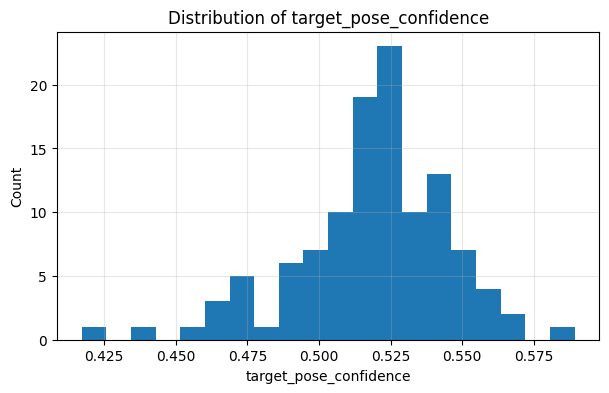

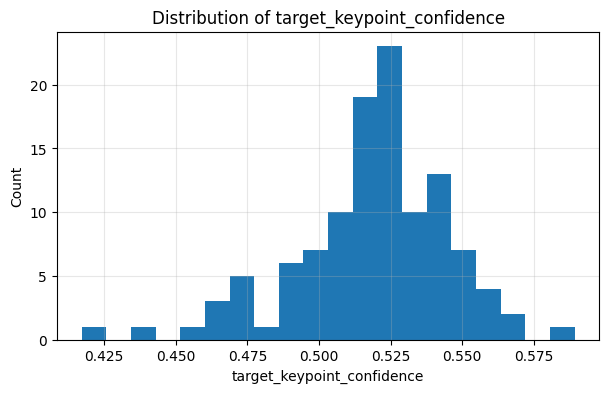

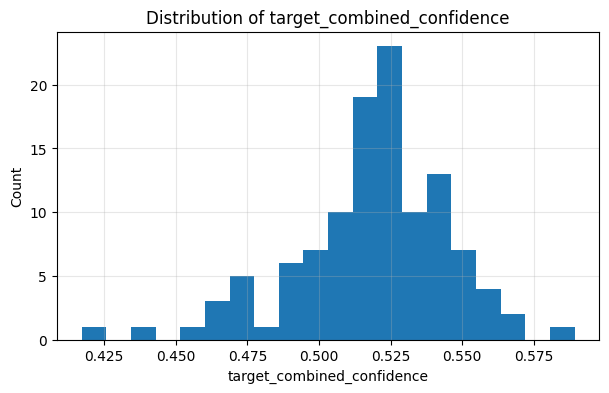

In [54]:
target_cols = [
    "target_pose_confidence",
    "target_keypoint_confidence",
    "target_combined_confidence",
]

display(kept_catalog_df[target_cols].describe())

for col in target_cols:
    plt.figure(figsize=(7, 4))
    plt.hist(kept_catalog_df[col], bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.grid(True, alpha=0.3)
    plt.show()

In [55]:
label_share_df = kept_catalog_df[
    [
        "sequence_id",
        "n_frames",
        "target_pose_confidence",
        "target_keypoint_confidence",
        "target_combined_confidence",
        "min_keypoint_confidence",
        "p10_keypoint_confidence",
        "fraction_keypoints_below_030",
        "fraction_frames_with_any_keypoint_below_030",
        "pose_score_source",
    ]
].copy()

label_share_df["quality_label"] = label_share_df["target_combined_confidence"].apply(
    lambda score: "accept" if score >= ACCEPT_THRESHOLD
    else "warn" if score >= WARN_THRESHOLD
    else "reject"
)

display(label_share_df.head(20))

label_share_path = RESULTS_DIR / "a14_shared_recording_quality_labels.csv"
label_share_df.to_csv(label_share_path, index=False)

print("Saved shared labels to:", label_share_path)
print("Label distribution:")
display(
    label_share_df["quality_label"]
    .value_counts()
    .rename_axis("quality_label")
    .reset_index(name="count")
)

,sequence_id,n_frames,target_pose_confidence,target_keypoint_confidence,target_combined_confidence,min_keypoint_confidence,p10_keypoint_confidence,fraction_keypoints_below_030,fraction_frames_with_any_keypoint_below_030,pose_score_source,quality_label
0,A1,229,0.589341,0.589341,0.589341,0.1516,0.41990,0.012429,0.148472,mean_keypoint_fallback,accept
1,G01,254,0.546313,0.546313,0.546313,0.1342,0.36831,0.039976,0.401575,mean_keypoint_fallback,accept
2,G02,314,0.554782,0.554782,0.554782,0.0511,0.37742,0.050710,0.423567,mean_keypoint_fallback,accept
3,G03,250,0.547615,0.547615,0.547615,0.0435,0.35049,0.063692,0.420000,mean_keypoint_fallback,accept
4,G04,219,0.493673,0.493673,0.493673,0.0232,0.21594,0.154197,0.666667,mean_keypoint_fallback,reject
5,G05,247,0.500050,0.500050,0.500050,0.0200,0.22290,0.177826,0.805668,mean_keypoint_fallback,warn
6,G06,317,0.556305,0.556304,0.556304,0.0576,0.38310,0.033972,0.328076,mean_keypoint_fallback,accept
7,G07,292,0.567798,0.567798,0.567798,0.0657,0.39620,0.031085,0.311644,mean_keypoint_fallback,accept
8,G08,259,0.557760,0.557760,0.557760,0.0737,0.38390,0.036234,0.335907,mean_keypoint_fallback,accept
9,G09,261,0.557105,0.557105,0.557105,0.0442,0.37444,0.036841,0.352490,mean_keypoint_fallback,accept


Saved shared labels to: reporting\results\a14_shared_recording_quality_labels.csv
Label distribution:


,quality_label,count
0,warn,55
1,accept,37
2,reject,22


## Feature preparation

The champion model uses the first 10 frames from each recording.

For each frame, the model uses:

- pose confidence
- 13 keypoint confidence scores

This gives:

\[
10 \times 14 = 140
\]

input values per recording.

This was chosen because confidence scores directly describe whether MoveNet is stable.  
Coordinate-based features were considered, but they add more complexity and were not necessary for this recording-quality task.

In [56]:
def take_first_frames(df, seq_len=SEQ_LEN):
    df = df.copy().reset_index(drop=True)

    if len(df) >= seq_len:
        return df.iloc[:seq_len].copy()

    missing = seq_len - len(df)
    padding = pd.concat([df.iloc[[-1]].copy()] * missing, ignore_index=True)
    return pd.concat([df, padding], ignore_index=True)


def build_xy(sequence_ids, sequence_dfs, labels_df, scaler=None, fit_scaler=False):
    X_rows = []
    y_rows = []

    label_lookup = labels_df.set_index("sequence_id")

    for sequence_id in sequence_ids:
        df = sequence_dfs[sequence_id]
        first_frames = take_first_frames(df, SEQ_LEN)

        X = first_frames[FEATURE_COLS].astype(float).fillna(0.0).values.reshape(-1)
        y = label_lookup.loc[
            sequence_id,
            [
                "target_pose_confidence",
                "target_keypoint_confidence",
                "target_combined_confidence",
            ],
        ].astype(float).values

        X_rows.append(X)
        y_rows.append(y)

    X = np.asarray(X_rows, dtype=np.float32)
    y = np.asarray(y_rows, dtype=np.float32)

    if fit_scaler:
        scaler = MinMaxScaler()
        X = scaler.fit_transform(X)
    elif scaler is not None:
        X = scaler.transform(X)

    return X.astype(np.float32), y.astype(np.float32), scaler

In [57]:
sequence_ids = kept_catalog_df["sequence_id"].tolist()

train_val_ids, test_ids = train_test_split(
    sequence_ids,
    test_size=0.20,
    random_state=RANDOM_SEED,
)

train_ids, val_ids = train_test_split(
    train_val_ids,
    test_size=0.10,
    random_state=RANDOM_SEED,
)

X_train, y_train, scaler = build_xy(
    train_ids,
    sequence_dfs,
    kept_catalog_df,
    scaler=None,
    fit_scaler=True,
)

X_val, y_val, _ = build_xy(
    val_ids,
    sequence_dfs,
    kept_catalog_df,
    scaler=scaler,
    fit_scaler=False,
)

X_test, y_test, _ = build_xy(
    test_ids,
    sequence_dfs,
    kept_catalog_df,
    scaler=scaler,
    fit_scaler=False,
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (81, 140) (81, 3)
Validation: (10, 140) (10, 3)
Test: (23, 140) (23, 3)


In [58]:
class ConfidenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


def make_loader(X, y, batch_size=BATCH_SIZE, shuffle=False):
    dataset = ConfidenceDataset(X, y)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )


train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val, shuffle=False)
test_loader = make_loader(X_test, y_test, shuffle=False)

In [59]:
class DenseConfidenceRegressor(nn.Module):
    def __init__(self, input_dim, hidden_dims=(16, 8), dropout=0.05, output_dim=3):
        super().__init__()

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hidden_dim

        layers.append(nn.Linear(current_dim, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


input_dim = X_train.shape[1]

model = DenseConfidenceRegressor(
    input_dim=input_dim,
    hidden_dims=(16, 8),
    dropout=0.05,
    output_dim=3,
).to(DEVICE)

print(model)
print("Trainable parameters:", count_trainable_parameters(model))

DenseConfidenceRegressor(
  (network): Sequential(
    (0): Linear(in_features=140, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.05, inplace=False)
    (3): Linear(in_features=16, out_features=8, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.05, inplace=False)
    (6): Linear(in_features=8, out_features=3, bias=True)
  )
)
Trainable parameters: 2419


## Champion model

The final champion model is:

- Dense neural network
- Input: first 10 frames of pose/keypoint confidence scores
- Hidden layers: 16 and 8 neurons
- Dropout: 0.05
- Output: 3 regression targets
  - pose confidence
  - keypoint confidence
  - combined confidence

This model was selected because it gave a good balance between:

- prediction performance
- low number of parameters
- low runtime cost
- practical online use

The full exploratory notebook tested more variants.  
This report notebook retrains only the chosen champion configuration.

In [60]:
def train_one_model(model, train_loader, val_loader, learning_rate, epochs, patience):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience_counter = 0

    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)

                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)
                val_losses.append(loss.item())

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            best_epoch = epoch
            patience_counter = 0
        else:
            patience_counter += 1

        if epoch % 10 == 0 or epoch == 1:
            print(
                f"Epoch {epoch:03d} | "
                f"train loss = {train_loss:.6f} | "
                f"val loss = {val_loss:.6f}"
            )

        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch}. Best epoch: {best_epoch}")
            break

    model.load_state_dict(best_state)

    history_df = pd.DataFrame(history)

    train_summary = {
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_ran": len(history_df),
    }

    return model, history_df, train_summary

In [61]:
start_time = time.perf_counter()

model, history_df, train_summary = train_one_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    learning_rate=LEARNING_RATE,
    epochs=EPOCHS,
    patience=PATIENCE,
)

training_time_seconds = time.perf_counter() - start_time

print("Training summary:")
print(train_summary)
print("Training time seconds:", training_time_seconds)

history_path = RESULTS_DIR / "a14_report_champion_training_history.csv"
history_df.to_csv(history_path, index=False)
print("Saved:", history_path)

Epoch 001 | train loss = 0.422278 | val loss = 0.340661
Epoch 010 | train loss = 0.044641 | val loss = 0.024425
Epoch 020 | train loss = 0.021150 | val loss = 0.018425
Epoch 030 | train loss = 0.028016 | val loss = 0.015136
Epoch 040 | train loss = 0.012714 | val loss = 0.012518
Epoch 050 | train loss = 0.024382 | val loss = 0.010162
Epoch 060 | train loss = 0.016667 | val loss = 0.008463
Epoch 070 | train loss = 0.013770 | val loss = 0.006941
Epoch 080 | train loss = 0.016796 | val loss = 0.005973
Epoch 090 | train loss = 0.014353 | val loss = 0.005028
Epoch 100 | train loss = 0.010319 | val loss = 0.004131
Epoch 110 | train loss = 0.009111 | val loss = 0.003638
Epoch 120 | train loss = 0.021496 | val loss = 0.003379
Training summary:
{'best_val_loss': 0.0033575964625924826, 'best_epoch': 119, 'epochs_ran': 120}
Training time seconds: 1.7562964999960968
Saved: reporting\results\a14_report_champion_training_history.csv


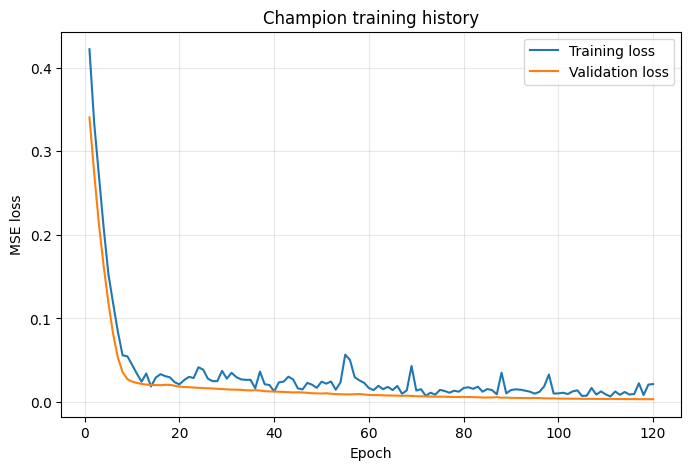

In [62]:
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Training loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Champion training history")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [63]:
TARGET_NAMES = [
    "pose_confidence",
    "keypoint_confidence",
    "combined_confidence",
]


def predict_loader(model, loader):
    model.eval()
    y_true_list = []
    y_pred_list = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            predictions = model(X_batch).cpu().numpy()

            y_pred_list.append(predictions)
            y_true_list.append(y_batch.numpy())

    y_true = np.vstack(y_true_list)
    y_pred = np.vstack(y_pred_list)

    return y_true, y_pred


def regression_metrics(y_true, y_pred, split_name):
    rows = []

    for i, target_name in enumerate(TARGET_NAMES):
        mae = mean_absolute_error(y_true[:, i], y_pred[:, i])
        mse = mean_squared_error(y_true[:, i], y_pred[:, i])
        rmse = np.sqrt(mse)
        r2 = r2_score(y_true[:, i], y_pred[:, i])

        rows.append({
            "split": split_name,
            "target": target_name,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R2": r2,
        })

    return pd.DataFrame(rows)


y_train_true, y_train_pred = predict_loader(model, train_loader)
y_val_true, y_val_pred = predict_loader(model, val_loader)
y_test_true, y_test_pred = predict_loader(model, test_loader)

metrics_df = pd.concat([
    regression_metrics(y_train_true, y_train_pred, "train"),
    regression_metrics(y_val_true, y_val_pred, "validation"),
    regression_metrics(y_test_true, y_test_pred, "test"),
], ignore_index=True)

display(metrics_df)

metrics_path = RESULTS_DIR / "a14_report_champion_regression_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)
print("Saved:", metrics_path)

,split,target,MAE,MSE,RMSE,R2
0,train,pose_confidence,0.040381,0.002884,0.053702,-3.390154
1,train,keypoint_confidence,0.017281,0.000528,0.022981,0.196052
2,train,combined_confidence,0.031778,0.001748,0.041804,-1.660331
3,validation,pose_confidence,0.063211,0.006439,0.080242,-4.075911
4,validation,keypoint_confidence,0.022784,0.000962,0.031016,0.241633
5,validation,combined_confidence,0.040168,0.002672,0.051691,-1.106403
6,test,pose_confidence,0.049970,0.004586,0.067716,-5.487615
7,test,keypoint_confidence,0.016408,0.000536,0.023161,0.241068
8,test,combined_confidence,0.033000,0.002170,0.046580,-2.069647


Saved: reporting\results\a14_report_champion_regression_metrics.csv


## Regression evaluation

The model is trained as a regression model because the original targets are continuous confidence scores.

The most important target is the combined confidence score because it is used for the final practical decision.

The MAE tells us the average absolute difference between the true confidence score and the predicted confidence score.  
For example, an MAE of `0.02` means that the predicted confidence is on average about `0.02` away from the target value.

The regression R2 is weak because the target confidence scores lie in a narrow range.  
However, the combined-confidence MAE is around 0.03, which is acceptable for the practical threshold-based decision.  
The ROC-AUC on all recordings is higher than the three-class decision accuracy, which suggests that the model is better at ranking usable vs reject recordings than at exactly separating reject, warn, and accept.

In [64]:
test_eval_df = pd.DataFrame({
    "sequence_id": test_ids,
    "true_pose_confidence": y_test_true[:, 0],
    "predicted_pose_confidence": y_test_pred[:, 0],
    "true_keypoint_confidence": y_test_true[:, 1],
    "predicted_keypoint_confidence": y_test_pred[:, 1],
    "true_combined_confidence": y_test_true[:, 2],
    "predicted_combined_confidence": y_test_pred[:, 2],
})

test_eval_df["pose_absolute_error"] = (
    test_eval_df["true_pose_confidence"] - test_eval_df["predicted_pose_confidence"]
).abs()

test_eval_df["keypoint_absolute_error"] = (
    test_eval_df["true_keypoint_confidence"] - test_eval_df["predicted_keypoint_confidence"]
).abs()

test_eval_df["combined_absolute_error"] = (
    test_eval_df["true_combined_confidence"] - test_eval_df["predicted_combined_confidence"]
).abs()

display(test_eval_df.head())

test_eval_path = RESULTS_DIR / "a14_report_champion_test_predictions.csv"
test_eval_df.to_csv(test_eval_path, index=False)
print("Saved:", test_eval_path)

,sequence_id,true_pose_confidence,predicted_pose_confidence,true_keypoint_confidence,predicted_keypoint_confidence,true_combined_confidence,predicted_combined_confidence,pose_absolute_error,keypoint_absolute_error,combined_absolute_error
0,W10,0.536649,0.678222,0.536649,0.539334,0.536649,0.616415,0.141573,0.002685,0.079765
1,G04,0.493673,0.538346,0.493673,0.522223,0.493673,0.526881,0.044673,0.028550,0.033208
2,G50,0.528185,0.576582,0.528185,0.526613,0.528185,0.548538,0.048397,0.001572,0.020354
3,G81,0.551501,0.590728,0.551501,0.528466,0.551501,0.558797,0.039227,0.023035,0.007296
4,G20,0.541748,0.527272,0.541748,0.520689,0.541748,0.518035,0.014476,0.021059,0.023714


Saved: reporting\results\a14_report_champion_test_predictions.csv


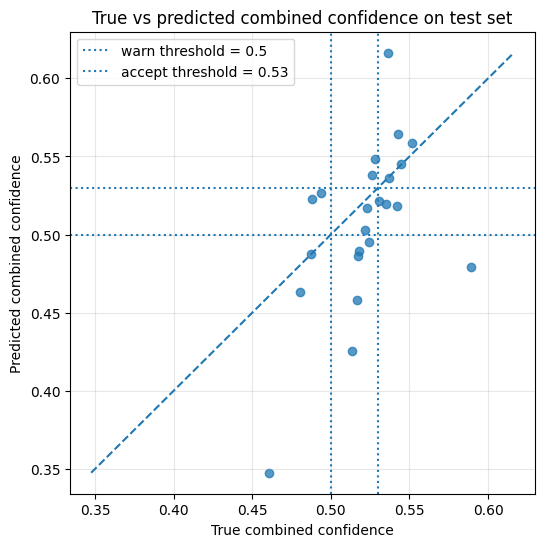

In [65]:
plt.figure(figsize=(6, 6))
plt.scatter(
    test_eval_df["true_combined_confidence"],
    test_eval_df["predicted_combined_confidence"],
    alpha=0.75,
)

min_value = min(
    test_eval_df["true_combined_confidence"].min(),
    test_eval_df["predicted_combined_confidence"].min(),
)
max_value = max(
    test_eval_df["true_combined_confidence"].max(),
    test_eval_df["predicted_combined_confidence"].max(),
)

plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.axhline(WARN_THRESHOLD, linestyle=":", label=f"warn threshold = {WARN_THRESHOLD}")
plt.axhline(ACCEPT_THRESHOLD, linestyle=":", label=f"accept threshold = {ACCEPT_THRESHOLD}")
plt.axvline(WARN_THRESHOLD, linestyle=":")
plt.axvline(ACCEPT_THRESHOLD, linestyle=":")

plt.xlabel("True combined confidence")
plt.ylabel("Predicted combined confidence")
plt.title("True vs predicted combined confidence on test set")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Interpretation of the results

The regression R2 scores are weak, especially for pose and combined confidence.  
This is partly because the confidence values are located in a narrow range, which makes R2 sensitive.

The combined-confidence MAE on the test set is approximately 0.033.  
This means that the predicted combined confidence is on average about 0.033 away from the target confidence score.

The three-class decision accuracy is modest, but the ROC-AUC on all recordings is around 0.81.  
This indicates that the model is better at ranking recordings as usable versus reject than at perfectly separating the three classes `reject`, `warn`, and `accept`.

Therefore, the model should be interpreted as a practical early-warning model rather than a perfect recording-quality classifier.

## Practical decision thresholds and all-recording evaluation

The model predicts continuous confidence values.  
To make this usable in the application, the confidence score is converted into a practical decision.

The final calibrated thresholds are:

- `accept` if combined confidence is at least `0.53`
- `warn` if combined confidence is at least `0.50`
- `reject` otherwise

The independent test split is still used for the main regression metrics.  
For the confusion matrix and ROC-AUC curve, all usable recordings are shown to make the decision behavior easier to inspect visually.

This all-recording evaluation should therefore be interpreted as a diagnostic visualization, not as the main independent test-set result.

In [66]:
# Evaluate the trained champion model on ALL usable recordings.
# This is useful for report visualization, but it is not an independent test-set result
# because it includes recordings that were used during training.

def decision_from_score(score, accept_threshold=ACCEPT_THRESHOLD, warn_threshold=WARN_THRESHOLD):
    if score >= accept_threshold:
        return "accept"
    elif score >= warn_threshold:
        return "warn"
    else:
        return "reject"


# Important:
# If the artifact-saving cell has been run before this cell, the model may have been moved to CPU.
# Move it back to the active DEVICE before prediction.
model = model.to(DEVICE)
model.eval()

X_all, y_all, _ = build_xy(
    sequence_ids,
    sequence_dfs,
    kept_catalog_df,
    scaler=scaler,
    fit_scaler=False,
)

all_loader = make_loader(X_all, y_all, shuffle=False)

y_all_true, y_all_pred = predict_loader(model, all_loader)

all_eval_df = pd.DataFrame({
    "sequence_id": sequence_ids,
    "true_pose_confidence": y_all_true[:, 0],
    "predicted_pose_confidence": y_all_pred[:, 0],
    "true_keypoint_confidence": y_all_true[:, 1],
    "predicted_keypoint_confidence": y_all_pred[:, 1],
    "true_combined_confidence": y_all_true[:, 2],
    "predicted_combined_confidence": y_all_pred[:, 2],
})

all_eval_df["true_decision"] = all_eval_df["true_combined_confidence"].apply(decision_from_score)
all_eval_df["predicted_decision"] = all_eval_df["predicted_combined_confidence"].apply(decision_from_score)

display(all_eval_df.head())

print("Number of evaluated recordings:", len(all_eval_df))

print("\nTrue decision distribution:")
display(
    all_eval_df["true_decision"]
    .value_counts()
    .rename_axis("decision")
    .reset_index(name="count")
)

print("\nPredicted decision distribution:")
display(
    all_eval_df["predicted_decision"]
    .value_counts()
    .rename_axis("decision")
    .reset_index(name="count")
)

all_eval_path = RESULTS_DIR / "a14_report_all_recordings_predictions.csv"
all_eval_df.to_csv(all_eval_path, index=False)
print("Saved:", all_eval_path)

,sequence_id,true_pose_confidence,predicted_pose_confidence,true_keypoint_confidence,predicted_keypoint_confidence,true_combined_confidence,predicted_combined_confidence,true_decision,predicted_decision
0,A1,0.589341,0.472359,0.589341,0.513628,0.589341,0.479524,accept,reject
1,G01,0.546313,0.559509,0.546313,0.524863,0.546313,0.540931,accept,accept
2,G02,0.554782,0.427493,0.554782,0.507876,0.554782,0.448219,accept,reject
3,G03,0.547615,0.484887,0.547615,0.514309,0.547615,0.479193,accept,reject
4,G04,0.493673,0.538346,0.493673,0.522223,0.493673,0.526881,reject,warn


Number of evaluated recordings: 114

True decision distribution:


,decision,count
0,warn,55
1,accept,37
2,reject,22



Predicted decision distribution:


,decision,count
0,reject,51
1,warn,36
2,accept,27


Saved: reporting\results\a14_report_all_recordings_predictions.csv


## Confusion matrix for all recordings

The confusion matrix below uses all usable MoveNet CSV files.

The model still predicts continuous confidence scores.  
For the confusion matrix, the true and predicted combined confidence scores are converted into the three practical classes:

- `reject`
- `warn`
- `accept`

This shows how often the model gives the same practical recording-quality decision as the confidence-score label.

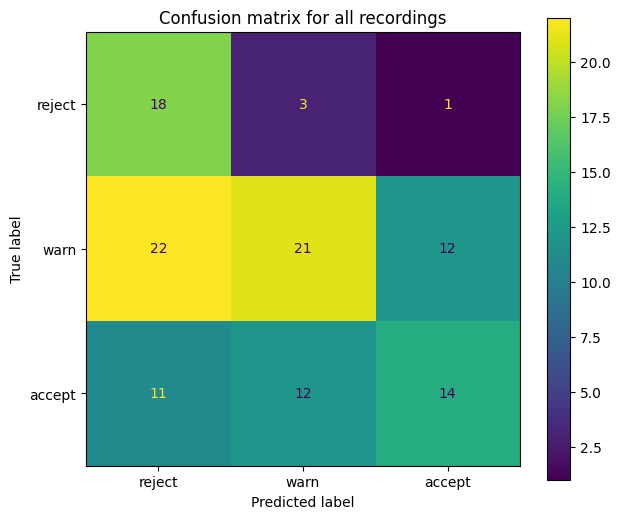

              precision    recall  f1-score   support

      reject       0.35      0.82      0.49        22
        warn       0.58      0.38      0.46        55
      accept       0.52      0.38      0.44        37

    accuracy                           0.46       114
   macro avg       0.48      0.53      0.46       114
weighted avg       0.52      0.46      0.46       114



In [67]:
decision_order = ["reject", "warn", "accept"]

cm = confusion_matrix(
    all_eval_df["true_decision"],
    all_eval_df["predicted_decision"],
    labels=decision_order,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=decision_order,
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, values_format="d")
plt.title("Confusion matrix for all recordings")
plt.show()

print(classification_report(
    all_eval_df["true_decision"],
    all_eval_df["predicted_decision"],
    labels=decision_order,
    zero_division=0,
))

## ROC-AUC curve for all recordings

ROC-AUC is calculated by converting the practical decision into a binary problem:

- `usable = 1` for `warn` or `accept`
- `usable = 0` for `reject`

The predicted combined confidence is used as the continuous score.

This ROC-AUC curve is calculated on all usable recordings.  
This gives a clearer visualization than using only the small test split, but it should be interpreted as a diagnostic plot rather than a fully independent test-set result.

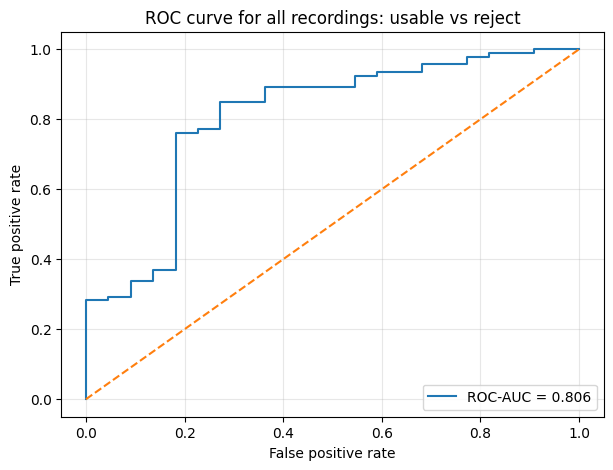

ROC-AUC on all recordings: 0.8063241106719368


In [68]:
all_eval_df["true_usable"] = (
    all_eval_df["true_combined_confidence"] >= WARN_THRESHOLD
).astype(int)

y_true_binary_all = all_eval_df["true_usable"]
y_score_all = all_eval_df["predicted_combined_confidence"]

if y_true_binary_all.nunique() == 2:
    fpr_all, tpr_all, thresholds_all = roc_curve(y_true_binary_all, y_score_all)
    roc_auc_all = auc(fpr_all, tpr_all)

    plt.figure(figsize=(7, 5))
    plt.plot(fpr_all, tpr_all, label=f"ROC-AUC = {roc_auc_all:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("ROC curve for all recordings: usable vs reject")
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()

    print("ROC-AUC on all recordings:", roc_auc_all)
else:
    print("ROC-AUC cannot be calculated because only one binary class is present.")
    display(
        y_true_binary_all
        .value_counts()
        .rename_axis("class")
        .reset_index(name="count")
    )

## Threshold calibration on the test split

A dead end during the assignment was using thresholds that were too strict.

The first threshold setting rejected too many videos, especially recordings from the Huawei MateBook 14 Pro laptop camera.  
The skeleton was not always perfect, but the recording was not necessarily completely unusable.

Therefore, a middle class, `warn`, was useful.  
Instead of only accepting or rejecting a video, the system can warn the user that the recording may be unstable.

The selected thresholds were:

- `accept_threshold = 0.53`
- `warn_threshold = 0.50`

In [69]:
threshold_candidates = [
    {"accept_threshold": 0.55, "warn_threshold": 0.50},
    {"accept_threshold": 0.54, "warn_threshold": 0.50},
    {"accept_threshold": 0.53, "warn_threshold": 0.50},
    {"accept_threshold": 0.52, "warn_threshold": 0.49},
    {"accept_threshold": 0.51, "warn_threshold": 0.48},
]

threshold_rows = []

for candidate in threshold_candidates:
    accept_threshold = candidate["accept_threshold"]
    warn_threshold = candidate["warn_threshold"]

    decisions = test_eval_df["predicted_combined_confidence"].apply(
        lambda score: decision_from_score(
            score,
            accept_threshold=accept_threshold,
            warn_threshold=warn_threshold,
        )
    )

    counts = decisions.value_counts()

    threshold_rows.append({
        "accept_threshold": accept_threshold,
        "warn_threshold": warn_threshold,
        "n_accept": int(counts.get("accept", 0)),
        "n_warn": int(counts.get("warn", 0)),
        "n_reject": int(counts.get("reject", 0)),
        "accept_fraction": float(counts.get("accept", 0) / len(decisions)),
        "warn_fraction": float(counts.get("warn", 0) / len(decisions)),
        "reject_fraction": float(counts.get("reject", 0) / len(decisions)),
    })

threshold_summary_df = pd.DataFrame(threshold_rows)
display(threshold_summary_df)

threshold_summary_path = RESULTS_DIR / "a14_report_threshold_calibration_summary.csv"
threshold_summary_df.to_csv(threshold_summary_path, index=False)
print("Saved:", threshold_summary_path)

,accept_threshold,warn_threshold,n_accept,n_warn,n_reject,accept_fraction,warn_fraction,reject_fraction
0,0.55,0.50,3,11,9,0.130435,0.478261,0.391304
1,0.54,0.50,5,9,9,0.217391,0.391304,0.391304
2,0.53,0.50,7,7,9,0.304348,0.304348,0.391304
3,0.52,0.49,10,5,8,0.434783,0.217391,0.347826
4,0.51,0.48,13,5,5,0.565217,0.217391,0.217391


Saved: reporting\results\a14_report_threshold_calibration_summary.csv


## Practical camera comparison

The model was tested with two different camera setups:

1. **Phone camera**
   - Recording from an iPhone 13 Pro in 4K
   - Higher recording quality
   - More stable skeleton
   - Expected to give higher confidence values

2. **Laptop camera**
   - Recording from a Huawei MateBook 14 Pro laptop camera
   - Lower recording quality
   - More skeleton glitches
   - Expected to give lower confidence values

This comparison was important because the laptop camera produced lower MoveNet confidence scores.  
A threshold that was too strict would reject too many laptop recordings, even when some of them were still usable.

For this report notebook, place the two MoveNet CSV files in the same folder as the notebook and name them with:

- `phone` in the filename for the iPhone recording
- `laptop` in the filename for the Huawei laptop recording

In [70]:
def predict_single_csv(csv_path):
    df = load_movenet_as_assignment_df(csv_path)
    df = df.dropna(subset=FEATURE_COLS).copy()

    first_frames = take_first_frames(df, SEQ_LEN)
    X = first_frames[FEATURE_COLS].astype(float).fillna(0.0).values.reshape(1, -1)
    X_scaled = scaler.transform(X).astype(np.float32)

    model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(X_scaled, dtype=torch.float32).to(DEVICE)).cpu().numpy()[0]

    observed_info = calculate_recording_confidence_targets(df)

    return {
        "file_name": Path(csv_path).name,
        "n_frames": len(df),
        "observed_pose_confidence_full_video": observed_info["target_pose_confidence"],
        "observed_keypoint_confidence_full_video": observed_info["target_keypoint_confidence"],
        "observed_combined_confidence_full_video": observed_info["target_combined_confidence"],
        "predicted_pose_confidence_first_10_frames": float(pred[0]),
        "predicted_keypoint_confidence_first_10_frames": float(pred[1]),
        "predicted_combined_confidence_first_10_frames": float(pred[2]),
        "decision": decision_from_score(float(pred[2])),
    }


# The report expects the practical camera-test CSV files to be placed
# in the same folder as this notebook.
#
# Example names:
# - phone_movenet.csv
# - laptop_movenet.csv
#
# The only requirement is that the filename contains either "phone" or "laptop".
camera_csv_files = sorted(Path(".").glob("*.csv"))

camera_rows = []

for csv_path in camera_csv_files:
    file_name_lower = csv_path.name.lower()

    if "phone" not in file_name_lower and "laptop" not in file_name_lower:
        continue

    row = predict_single_csv(csv_path)

    if "phone" in file_name_lower:
        row["camera_type"] = "phone"
    elif "laptop" in file_name_lower:
        row["camera_type"] = "laptop"

    camera_rows.append(row)

camera_eval_df = pd.DataFrame(camera_rows)

if len(camera_eval_df) == 0:
    print("No phone/laptop MoveNet CSV files were found.")
    print("Place the files in the same folder as the notebook and name them for example:")
    print("- phone_movenet.csv")
    print("- laptop_movenet.csv")
else:
    display(camera_eval_df.sort_values(["camera_type", "file_name"]).reset_index(drop=True))

    camera_eval_path = RESULTS_DIR / "a14_report_camera_test_predictions.csv"
    camera_eval_df.to_csv(camera_eval_path, index=False)
    print("Saved:", camera_eval_path)

,file_name,n_frames,observed_pose_confidence_full_video,observed_keypoint_confidence_full_video,observed_combined_confidence_full_video,predicted_pose_confidence_first_10_frames,predicted_keypoint_confidence_first_10_frames,predicted_combined_confidence_first_10_frames,decision,camera_type
0,laptop_movenet.csv,103,0.562532,0.562532,0.562532,0.266650,0.489592,0.358913,reject,laptop
1,iphone_movenet.csv,70,0.600279,0.600279,0.600279,0.690488,0.540058,0.616660,accept,phone


Saved: reporting\results\a14_report_camera_test_predictions.csv


,camera_type,n_recordings,mean_observed_combined_confidence,mean_predicted_combined_confidence
0,laptop,1,0.562532,0.358913
1,phone,1,0.600279,0.616660


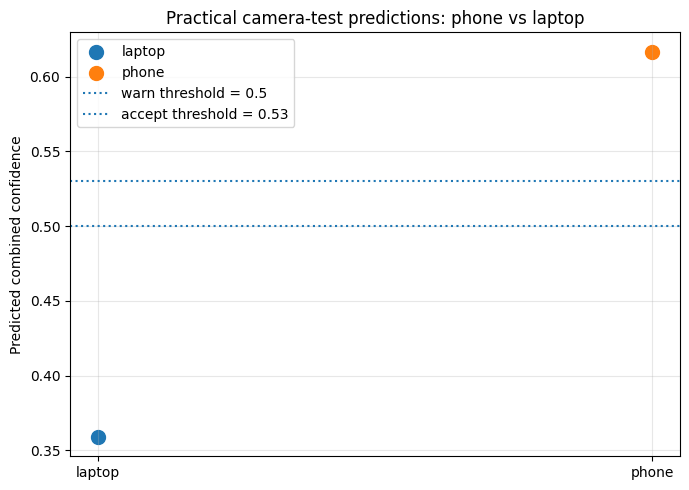

In [71]:
if len(camera_eval_df) > 0:
    camera_summary_df = (
        camera_eval_df
        .groupby("camera_type")
        .agg(
            n_recordings=("file_name", "count"),
            mean_observed_combined_confidence=("observed_combined_confidence_full_video", "mean"),
            mean_predicted_combined_confidence=("predicted_combined_confidence_first_10_frames", "mean"),
        )
        .reset_index()
    )

    display(camera_summary_df)

    plt.figure(figsize=(7, 5))

    for camera_type, group in camera_eval_df.groupby("camera_type"):
        plt.scatter(
            group["camera_type"],
            group["predicted_combined_confidence_first_10_frames"],
            s=100,
            label=camera_type,
        )

    plt.axhline(WARN_THRESHOLD, linestyle=":", label=f"warn threshold = {WARN_THRESHOLD}")
    plt.axhline(ACCEPT_THRESHOLD, linestyle=":", label=f"accept threshold = {ACCEPT_THRESHOLD}")

    plt.ylabel("Predicted combined confidence")
    plt.title("Practical camera-test predictions: phone vs laptop")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Dead ends and lessons learned

### Too strict thresholds

The first threshold setting was too strict.  
It rejected too many videos, especially when the recordings came from the Huawei MateBook 14 Pro laptop camera.

The iPhone 13 Pro 4K recordings produced more stable skeleton detections, but the laptop camera had more skeleton glitches and lower confidence values.  
Because of this, the final system uses both a warning threshold and an accept threshold.

### Larger models were not clearly better

Larger models were considered during the exploratory work, but they were not necessary for the final solution.  
The task is mainly about detecting recording quality, so the confidence scores themselves are already very informative.

The selected champion model is small and suitable for online decision-making.

### Coordinate features added unnecessary complexity

Coordinate features were also considered, but they make the model more sensitive to camera position, body placement, and framing.  
For this assignment, confidence scores were more directly related to the recording-quality problem.

Therefore, the final champion uses score-only features.

In [72]:
model_path = ARTIFACTS_DIR / "a14_report_trained_champion_model.pt"
scaler_path = ARTIFACTS_DIR / "a14_report_trained_champion_scaler.joblib"
config_path = ARTIFACTS_DIR / "a14_report_trained_champion_config.json"

torch.save(model.to("cpu").state_dict(), model_path)
model = model.to(DEVICE)
joblib.dump(scaler, scaler_path)

champion_config = {
    "name": "dense_scores_16_8",
    "model_family": "dense",
    "feature_set": "scores_only",
    "seq_len": SEQ_LEN,
    "feature_cols": FEATURE_COLS,
    "target_names": TARGET_NAMES,
    "hidden_dims": [16, 8],
    "dropout": 0.05,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "accept_threshold": ACCEPT_THRESHOLD,
    "warn_threshold": WARN_THRESHOLD,
    "pose_weight": POSE_WEIGHT,
    "keypoint_weight": KEYPOINT_WEIGHT,
    "n_parameters": count_trainable_parameters(model),
    "best_epoch": train_summary["best_epoch"],
    "best_val_loss": train_summary["best_val_loss"],
    "epochs_ran": train_summary["epochs_ran"],
}

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(champion_config, f, indent=2)

print("Saved model:", model_path)
print("Saved scaler:", scaler_path)
print("Saved config:", config_path)

Saved model: reporting\artifacts\a14_report_trained_champion_model.pt
Saved scaler: reporting\artifacts\a14_report_trained_champion_scaler.joblib
Saved config: reporting\artifacts\a14_report_trained_champion_config.json


## Final conclusion

The final A14 solution trains a small dense neural network that predicts recording quality from the first 10 frames of MoveNet output.

The model predicts:

- pose confidence
- keypoint confidence
- combined confidence

The combined confidence is then converted into:

- `accept`
- `warn`
- `reject`

The champion model is small, fast, and suitable for online use because it only needs the first few frames.

The practical camera comparison showed that the phone recording produced more stable skeleton detections, while the laptop camera produced lower confidence and more skeleton glitches.

Because of this, the threshold had to be adjusted.  
The final threshold setting uses:

- `accept_threshold = 0.53`
- `warn_threshold = 0.50`

This makes the model more useful in a realistic setting because lower-quality laptop recordings are not automatically rejected unless the predicted confidence is clearly too low.

This report notebook trains only the final champion model.  
The earlier exploratory notebooks contain the full hyperparameter search and additional experiments.